In [1]:
## Iris Boundary Animator
## Classifying setosa vsversicolor using two features 

In [2]:
import matplotlib.pyplot as plt 
import matplotlib.animation as animation 
import numpy as np 
from sklearn.datasets import load_iris

In [3]:
iris = load_iris()


mask = iris.target < 2
X = iris.data[mask, :2] ## Take two features: length and width
y = iris.target[mask]

X_mean = np.mean(X, axis = 0)
X_std = np.std(X, axis = 0)
X_scaled = (X-X_mean) / X_std

In [4]:
np.random.seed(42)
weights = np.random.randn(2)
bias = 0.0
lr = 0.1
epochs = 50 

history = []
num_samples = len(y)


for epoch in range(epochs):
    z = np.dot(X_scaled, weights) + bias
    prediction = 1 / (1+np.exp(-z))
    errors = prediction - y 

    dw = (1/num_samples) * np.dot(X_scaled.T, errors)
    db = (1 /num_samples) * np.sum(errors)

    weights -= lr * dw
    bias -= lr * db 

    history.append((weights.copy(), bias))

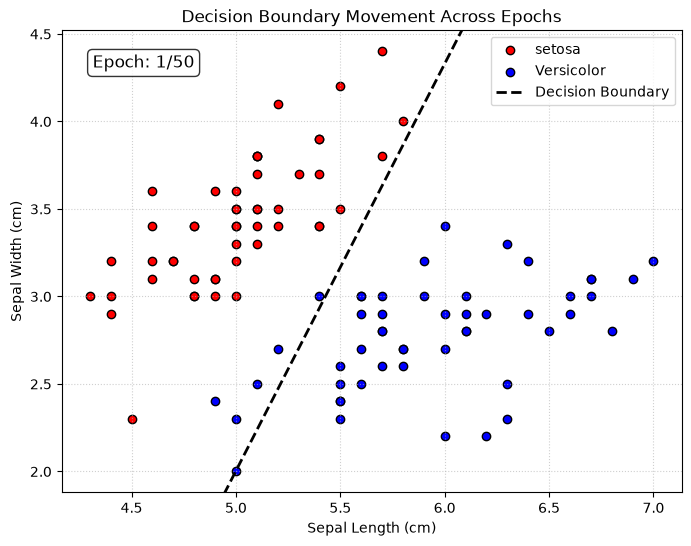

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

setosa_mask = y == 0 
versicolor_mask = y == 1 

ax.scatter(
    X[setosa_mask, 0],
    X[setosa_mask, 1],
    color = 'red',
    label = 'setosa',
    edgecolor = 'k',
)
ax.scatter(
    X[versicolor_mask, 0],
    X[versicolor_mask, 1],
    color='blue',
    label='Versicolor',
    edgecolor='k',
)

(line,) = ax.plot([], [], 'k--', linewidth=2, label='Decision Boundary')
epoch_text = ax.text(
    0.05,
    0.92,
    '',
    transform=ax.transAxes,
    fontsize=12,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
)


ax.set_xlabel('Sepal Length (cm)')
ax.set_ylabel('Sepal Width (cm)')
ax.set_title('Decision Boundary Movement Across Epochs')
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.6)


## Generate grid values along Sepal Length x-axis
x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)

def animate(frame):
    current_w, current_b = history[frame]

    # Convert boundary line back from scaled feature space to original scale
    # z = w1 * ((x1 - mean1)/std1) + w2 * ((x2 - mean2)/std2) + b = 0
    # Solving for x2:
    w1, w2 = current_w
    m1, m2 = X_mean
    s1, s2 = X_std

    # Unscaled boundary equation for x2:
    x2_vals = m2 - s2 * (w1 * (x1_vals - m1) / s1 + current_b) / w2

    line.set_data(x1_vals, x2_vals)
    epoch_text.set_text(f'Epoch: {frame + 1}/{epochs}')
    return line, epoch_text


# Create animation (100ms per epoch)
anim = animation.FuncAnimation(
    fig, animate, frames=len(history), interval=100, blit=True
)

plt.show()